# Signal/Noise Ratio

How do we calculate the SNR for our technical cases, and planning our observations? As a reminder, the signal-to-noise ratio is given by:

$$\rm{SNR} = \frac{N}{\sqrt{N+S+D+n_pR^2}},$$

where $N$ is the number of photo-electrons from the **object**, $S$ is the number of photo-electrons from the **sky**, $D$ is the total number of photo-electrons in my aperture from **dark current**, $R$ is the readout noise per pixel (in electrons) and $n_p$ is the number of pixels in my aperture.

## Predicting N

As always with SNR calcs, we start by predicting the number of photo-electrons we will detect from the source. The usual approach to doing this is to start by scaling from an object whose magnitude and expected flux is known:

$$m_1 - m_2 = -2.5 \log_{10} (F_1/F_2)$$

$$F_1/F_2 = 10^{-0.4(m_1-m_2)}$$

The flux of Vega is a typically used resource, and the table below shows the expected flux from Vega (converted to photons/s/cm $^2$/$\AA$), along with other quantities we will need. 

| Filter    | Efficiency Q | $F_{\rm vega}$ ($\gamma$/s/cm2/AA) | Bandwidth (AA) | 
| ------    | ------------ | ---------------------------------- | -------------- |
| H $\alpha$ | 0.41 | 717 | 70 |
| B         | 0.37 | 1170 | 720 |
| V | 0.42 | 1002 | 860 |
| R | 0.42 | 717 | 1330 |
| I | 0.22 | 471 | 1400 |

We also have a table of sky brightness.

| Filter | Bright (mag/sq. arcsec) | Grey (mag/sq. arcsec) | Dark (mag/sq. arcsec) | 
| ------ | ----------------------- | ----------------------| --------------------- |
| H $\alpha$ | 21.2 | 23.3 | 24.1 |
| B | 18.7 | 21.7 | 22.7 |
| V | 17.7 | 20.7 | 21.7 |
| R | 18.0 | 20.1 | 20.9 |
| I | 18.3 | 19.6 | 20.0 |

Finally, we also need the collecting area of the telescope: $A = 1850.4 {\rm cm}^2$, the dark current $D = 0.002 {\rm e}^-/{\rm pix}/s$, the unbinned platescale (0.28 arcsecs/pixel), the readout noise $R=12 {\rm e}^-/{\rm pix}$.


Let's use as an example a star with a magnitude of $V=17$. We'll use the astropy units library to make sure our unit conversions are good.

In [51]:
import numpy as np
from astropy import units as u 

# setup things given in question
tel_area = 1850.4 * u.cm**2
Q = 0.42 / u.photon
V = 17
f_vega = 1002 * u.photon/u.s/u.cm**2/u.Angstrom
bandpass = 860 * u.Angstrom

We now calculate the flux of the star using

$$F_* = F_{\rm vega} * 10^{-0.4(m_*-m_{\rm vega})} =F_{\rm vega} * 10^{-0.4m_*} $$

In [52]:
f_s = f_vega * 10**(-0.4*V)
f_s

<Quantity 0.00015881 ph / (Angstrom s cm2)>

## Correcting for exposure time, bandpass and exposure time.

Now we have the number of photons, per unit time, per unit area, per unit wavelength. We can get the total number of photons arriving at the telescope by multipling by the exposure time, collecting area and bandpass!

Let's assume a 30s exposure.

In [53]:
t_exp = 30 * u.s
n_photon = f_s * tel_area * bandpass * t_exp 

n_photon

<Quantity 7581.46347903 ph>

We see that the units are consistent with our expectation, giving us confident we've got this conversion right. Of course, not all photons are detected, so to get the detected number of **electrons** we need to multiply by the efficiency, $Q$.

In [54]:
N = n_photon * Q
N

<Quantity 3184.21466119>

In [55]:
N = f_vega * tel_area * bandpass * t_exp * Q * 10**(-0.4*V)
N

<Quantity 3184.21466119>

## Find S (photo electrons from sky).

How many photo-electrons from the sky? Suppose we observe when the Moon is 25% illuminated (Grey time), so $V_{\rm sky} = 20.7$ magnitudes *per square arcsecond*. 

We repeat the calculations above...

In [56]:
V_sky = 20.7
# note that the sky background is given in mag/arcsec^2
f_sky = f_vega * 10**(-0.4*V_sky) / u.arcsec**2
n_sky = f_sky * tel_area * bandpass * t_exp * Q

n_sky

<Quantity 105.43925718 1 / arcsec2>

Note here that we have the number of electrons from one sq arcsec of the sky. To find out how many electrons in total we need to find the size of our aperture in sq arcsecs!

For a star, our aperture will be a circle about 1.5x the seeing FWHM in radius. For a galaxy, the aperture must cover the whole galaxy, so it will be much larger... 

Let's assume the seeing is 2".

In [57]:
FWHM = 2 * u.arcsec
aperture_area = np.pi * (1.5*FWHM)**2

aperture_area

<Quantity 28.27433388 arcsec2>

In [58]:
S = n_sky * aperture_area
S

<Quantity 2981.22476181>

In [59]:
N, S

(<Quantity 3184.21466119>, <Quantity 2981.22476181>)

## How many pixels?

To find out how much dark current and readout noise we have, we need to know how many pixels our aperture covers. An **unbinned** pixel is 0.28 arcseconds.  So a binned pixel is $(0.28 n_b)^2$ arcseconds in area, where $n_b$ is the binning factor, e.g 1, 2, etc.  

In [60]:
binning = 1
pixel_area = (0.28 * binning * u.arcsec)**2

# number of pixels is just ratio of aperture area to pixel area
npix = aperture_area / pixel_area * u.pixel
npix

<Quantity 360.6420138 pix>

We can now calculate the dark current and readout noise....

In [61]:
dark_current = 0.002 /u.s/u.pixel

D = dark_current * t_exp * npix
D

<Quantity 21.63852083>

In [62]:
R = 12 / (u.pixel)**0.5

npix * R**2

<Quantity 51932.44998791>

Finally, we calculate the signal to noise!

In [63]:
SNR = N/np.sqrt(N+S+D+npix*R**2)


In [64]:
SNR

<Quantity 13.2081289>

Let's compare that to the best case, in which there is no dark current, readout noise etc.

In [65]:
np.sqrt(N)

<Quantity 56.428846>

In [66]:
print(f"N = {N:.0f}, S = {S:.0f}, D = {D:.0f}, R = {npix*R**2:.0f}")

N = 3184, S = 2981, D = 22, R = 51932


# Automating the calculation

Now that we've done one by hand, let's write a function that calculates the SNR. The inputs will be the filter name, the magnitude of our object, the sky brightness, the binning and the aperture area...

In [67]:
def calc_snr(mag, filter, t_exp, sky, binning, aperture_area):

    # make sure filter is lower case
    filter = filter.lower()

    # setup things given in question
    tel_area = 1850.4 * u.cm**2

    # we'll use dictionaries to store values that depend on the filter
    # efficiency
    Q = dict(ha=0.41/u.photon, b=0.37/u.photon, v=0.42/u.photon, 
             r=0.42/u.photon, i=0.22/u.photon)

    # vega fluxes
    f_vega_unit = u.photon/u.s/u.cm**2/u.Angstrom
    f_vega = dict(
        ha=717*f_vega_unit, b=1170*f_vega_unit, v=1002*f_vega_unit, 
        r=717*f_vega_unit, i=471*f_vega_unit)

    # bandwidths 
    banddpass= dict(
        ha=70*u.Angstrom, b=720*u.Angstrom, v=860*u.Angstrom, 
        r=1330*u.Angstrom, i=1400*u.Angstrom)

    sky_brightness = dict(
        bright=dict(ha=21.2, b=18.7, v=17.7, r=18.0, i=18.3),
        grey=dict(ha=23.3, b=21.7,v=20.7, r=20.1, i=19.6),                
        dark=dict(ha=24.1, b=22.7, v=21.7, r=20.9, i=20.0),
    )
    R = 12 / (u.pixel)**0.5
    dark_current = 0.002 / u.pixel/ u.s
    pixel_area = (0.28 * binning * u.arcsec)**2

    # electrons from object
    N = f_vega[filter] * 10**(-0.4*mag) * tel_area * banddpass[filter] * t_exp * Q[filter]
    # from sky
    m_sky = sky_brightness[sky][filter]
    S = (f_vega[filter] * 10**(-0.4*m_sky) * tel_area * banddpass[filter] 
         * t_exp * Q[filter] * aperture_area.to_value(u.arcsec**2))

    npix = aperture_area / pixel_area * u.pixel
    D = dark_current * t_exp * npix

    return N/np.sqrt(N+S+D+npix*R**2)



In [68]:
snr = calc_snr(17, 'v', 30*u.s, 'grey', 1, np.pi*(1.5*2*u.arcsec)**2)
print(snr)

13.208128899027784


Let's look at what could help improve the SNR. Read noise was a huge issue. We could bin the detector, averaging pixels before readout, so there is less read noise:

In [69]:
calc_snr(17, 'v', 30*u.s, 'grey', 4, np.pi*(1.5*2*u.arcsec)**2)

<Quantity 32.82072945>

The sky background was also nearly the same as the object flux. We could ask for dark time:

In [70]:
calc_snr(17, 'v', 30*u.s, 'dark', 4, np.pi*(1.5*2*u.arcsec)**2)

<Quantity 36.48180994>

Alternatively, we can hope for better seeing, spreading the starlight over fewer pixels... This reduces all of dark current, readout noise and sky background (for stars at least).

Text(0, 0.5, 'SNR')

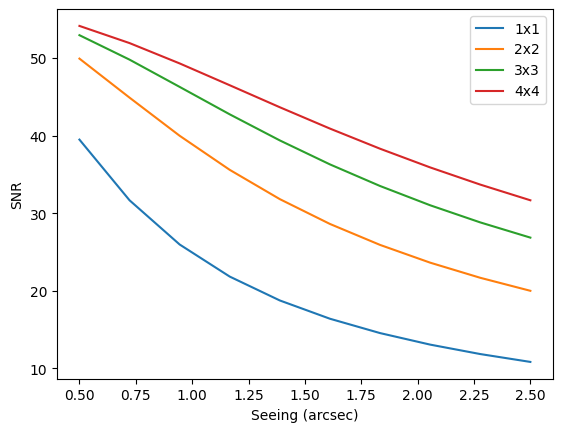

In [71]:
from matplotlib import pyplot as plt
%matplotlib inline

seeing = np.linspace(0.5, 2.5, 10) * u.arcsec
aperture_area = np.pi * (1.5*seeing)**2

for binning in (1, 2, 3, 4):
    snr = calc_snr(17, 'v', 30*u.s, 'dark', binning, aperture_area)
    plt.plot(seeing, snr, label=f'{binning}x{binning}')

plt.legend()
plt.xlabel('Seeing (arcsec)')
plt.ylabel('SNR')

In [72]:
calc_snr(9.1, 'r', 120*u.s, 'bright', 1, 7.1*5.5*u.arcmin**2)

<Quantity 623.4632034>

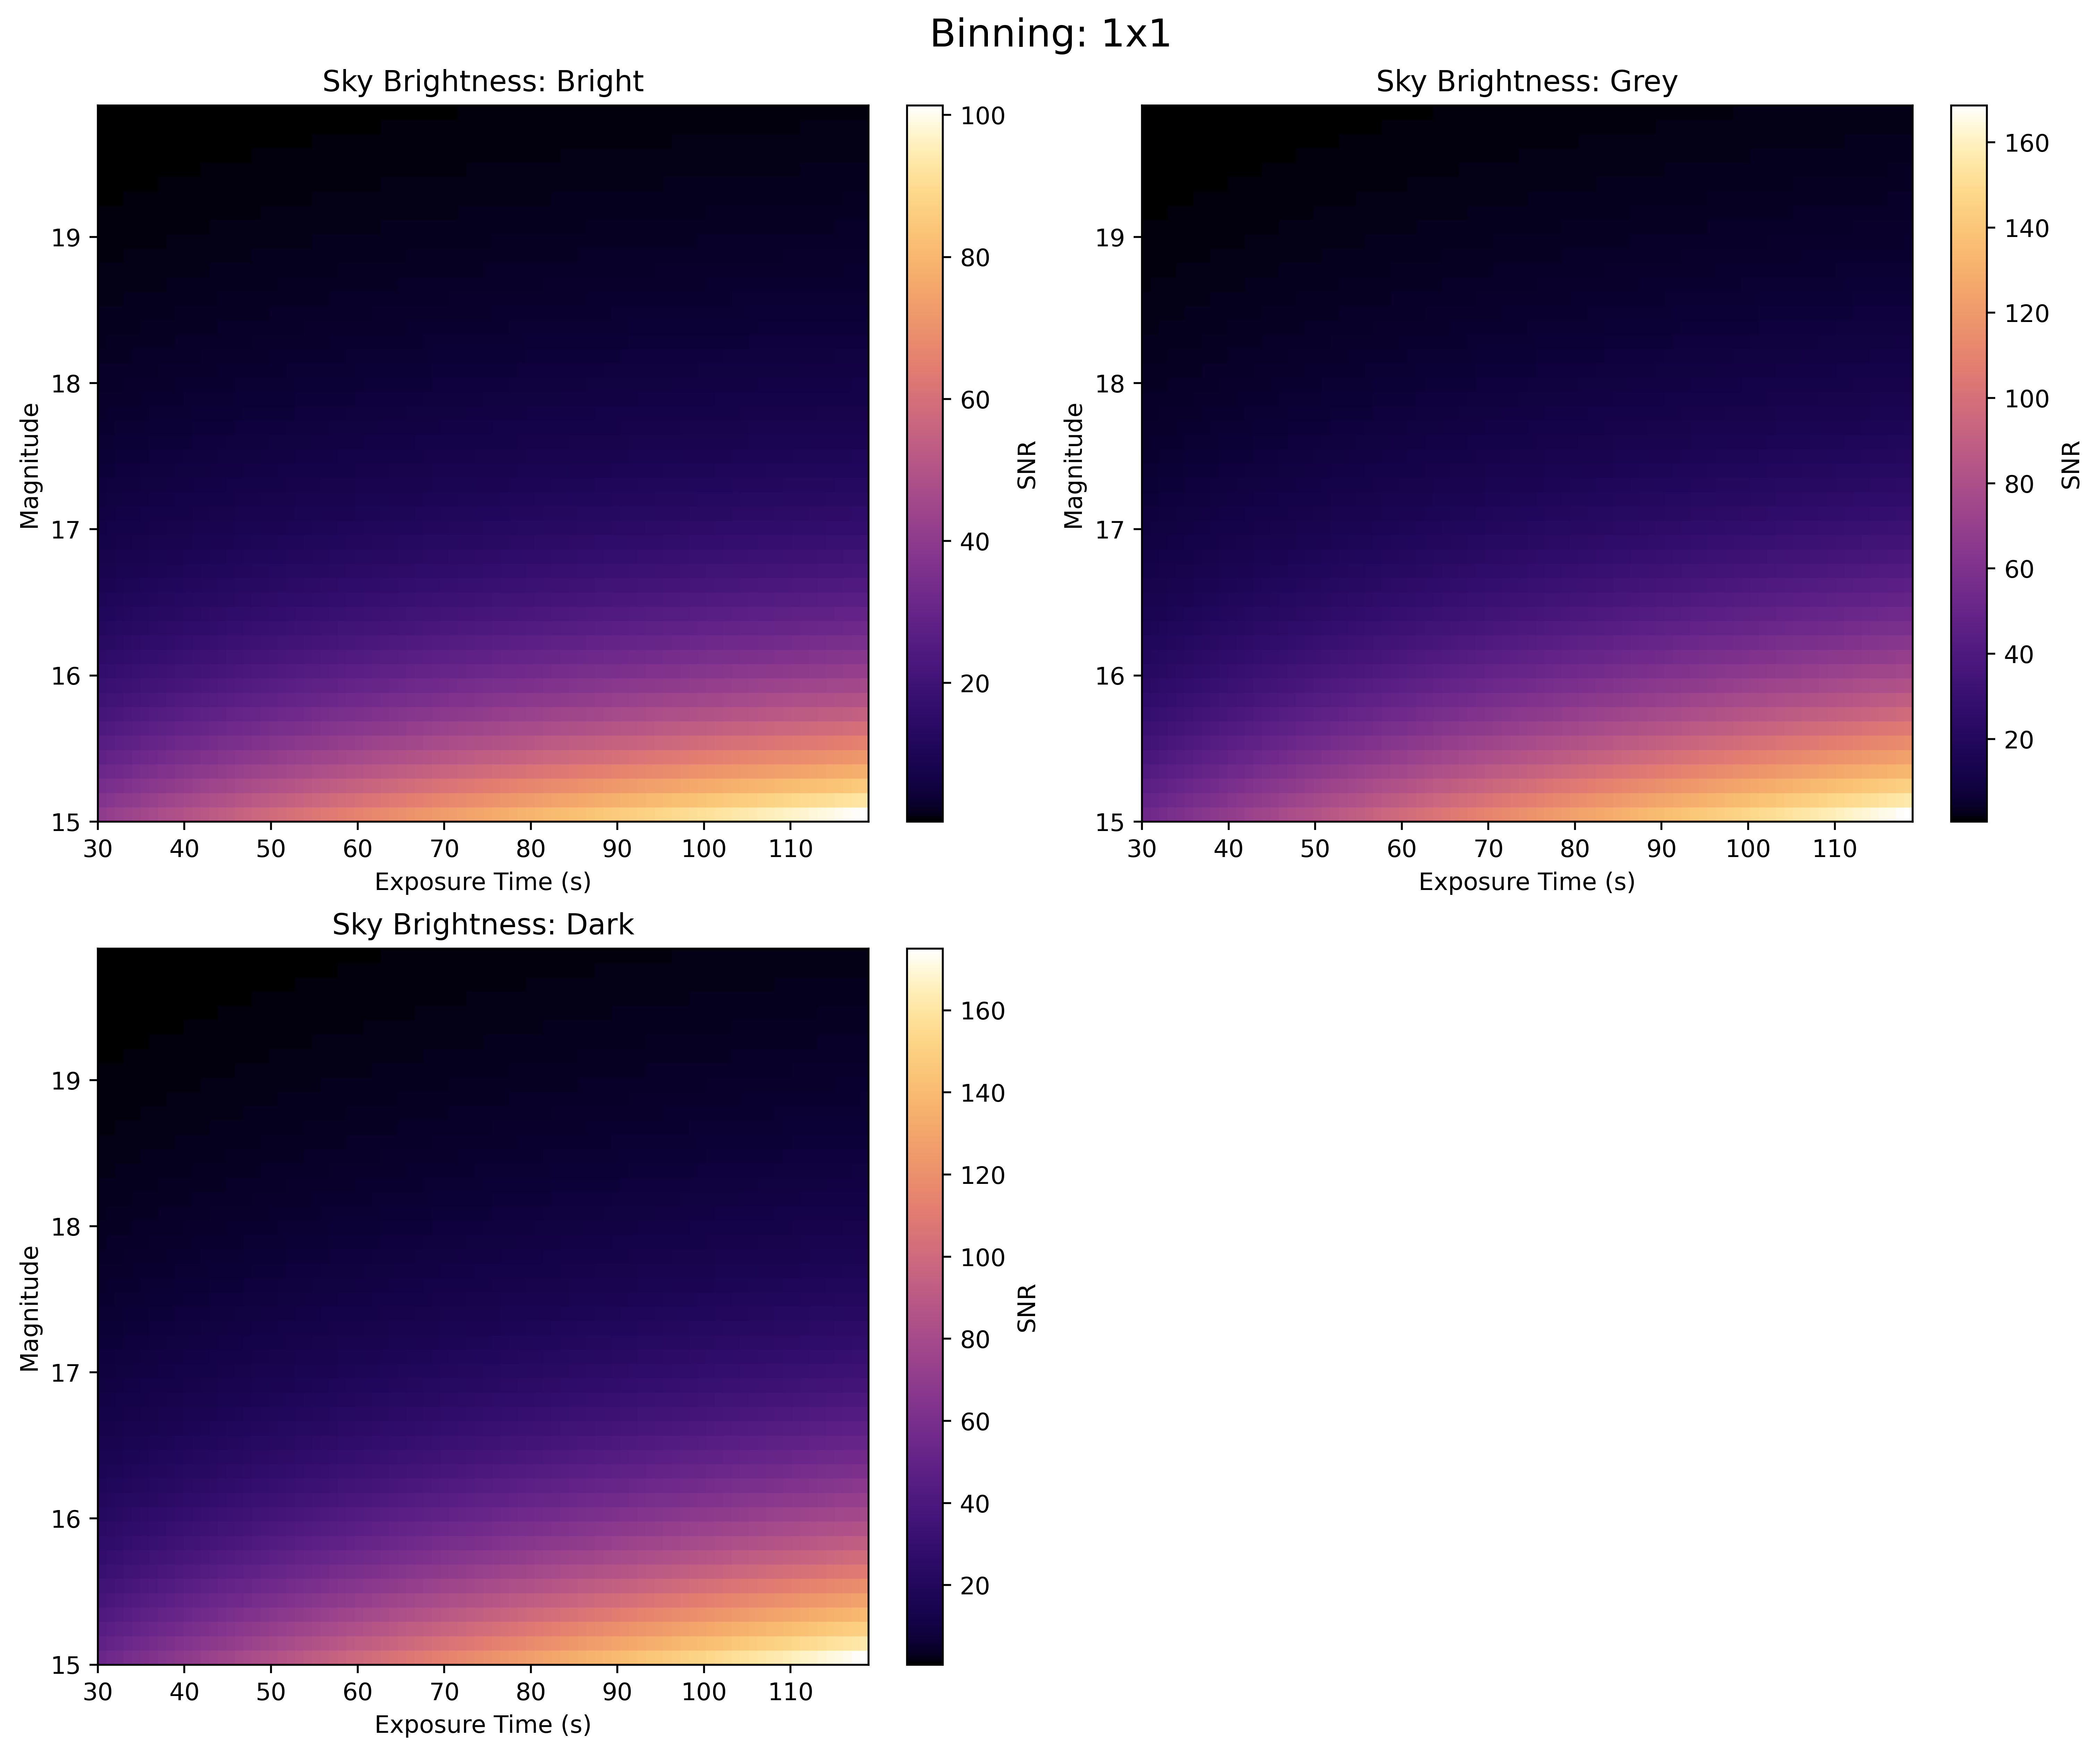

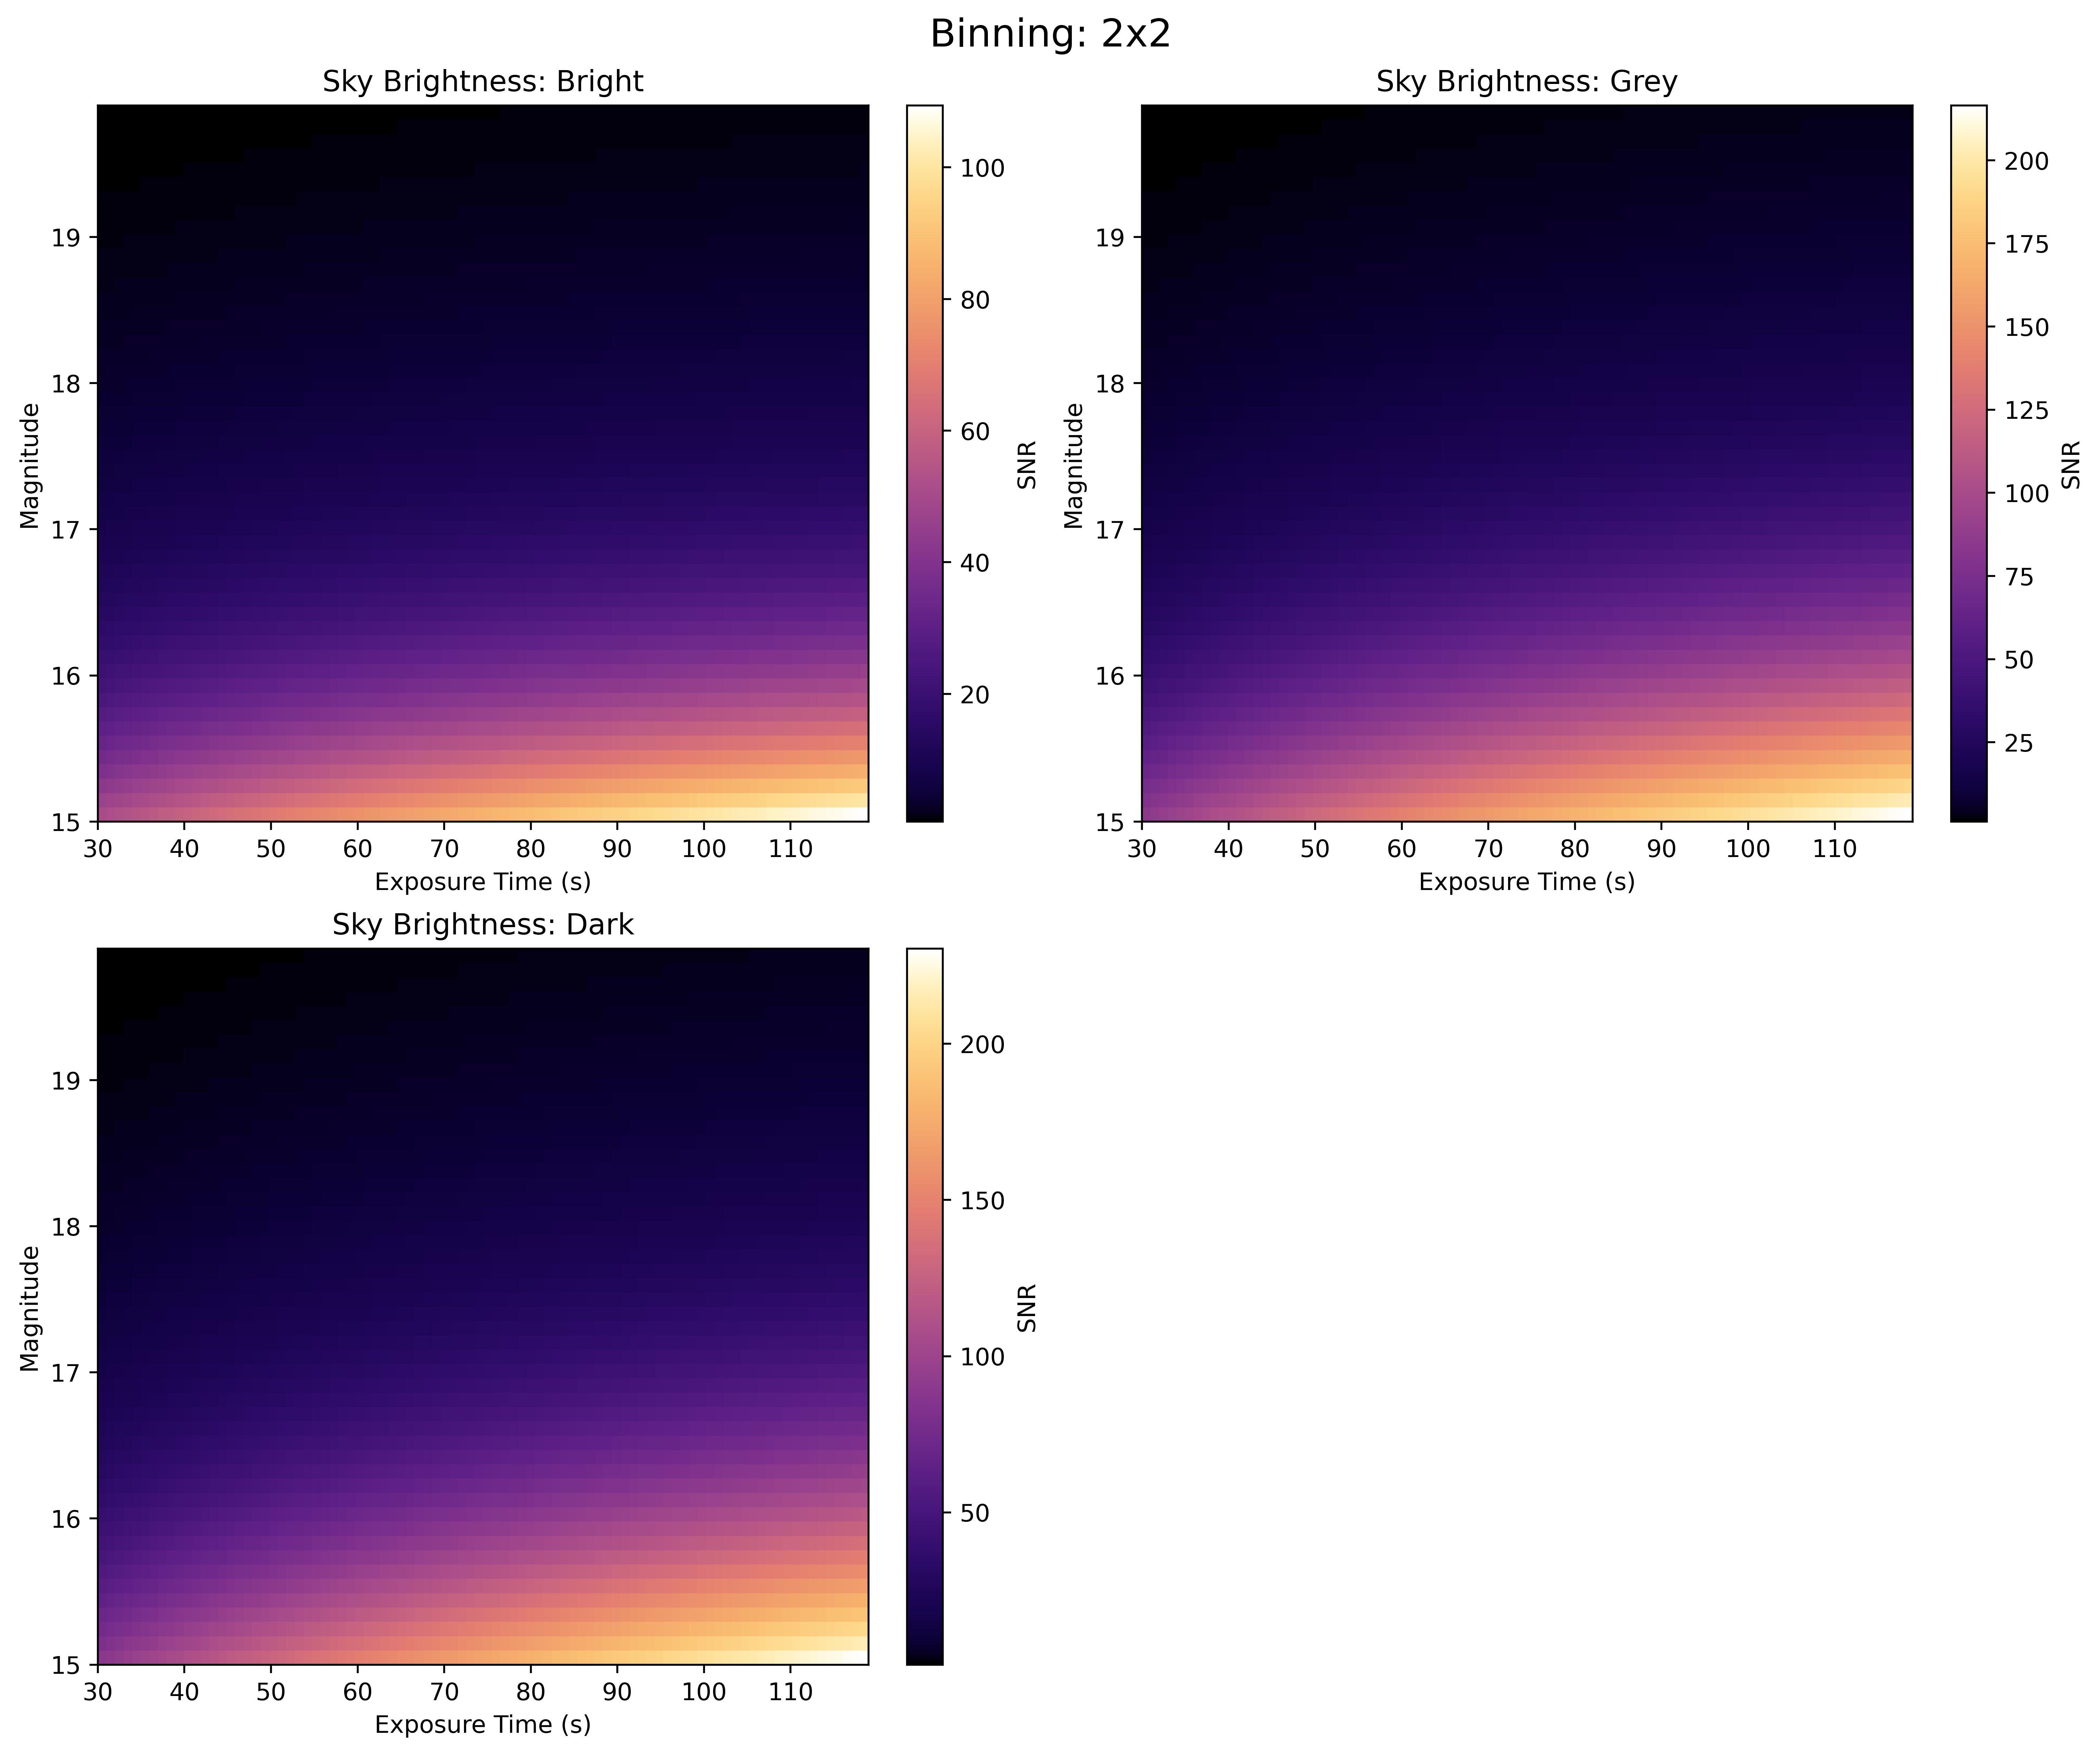

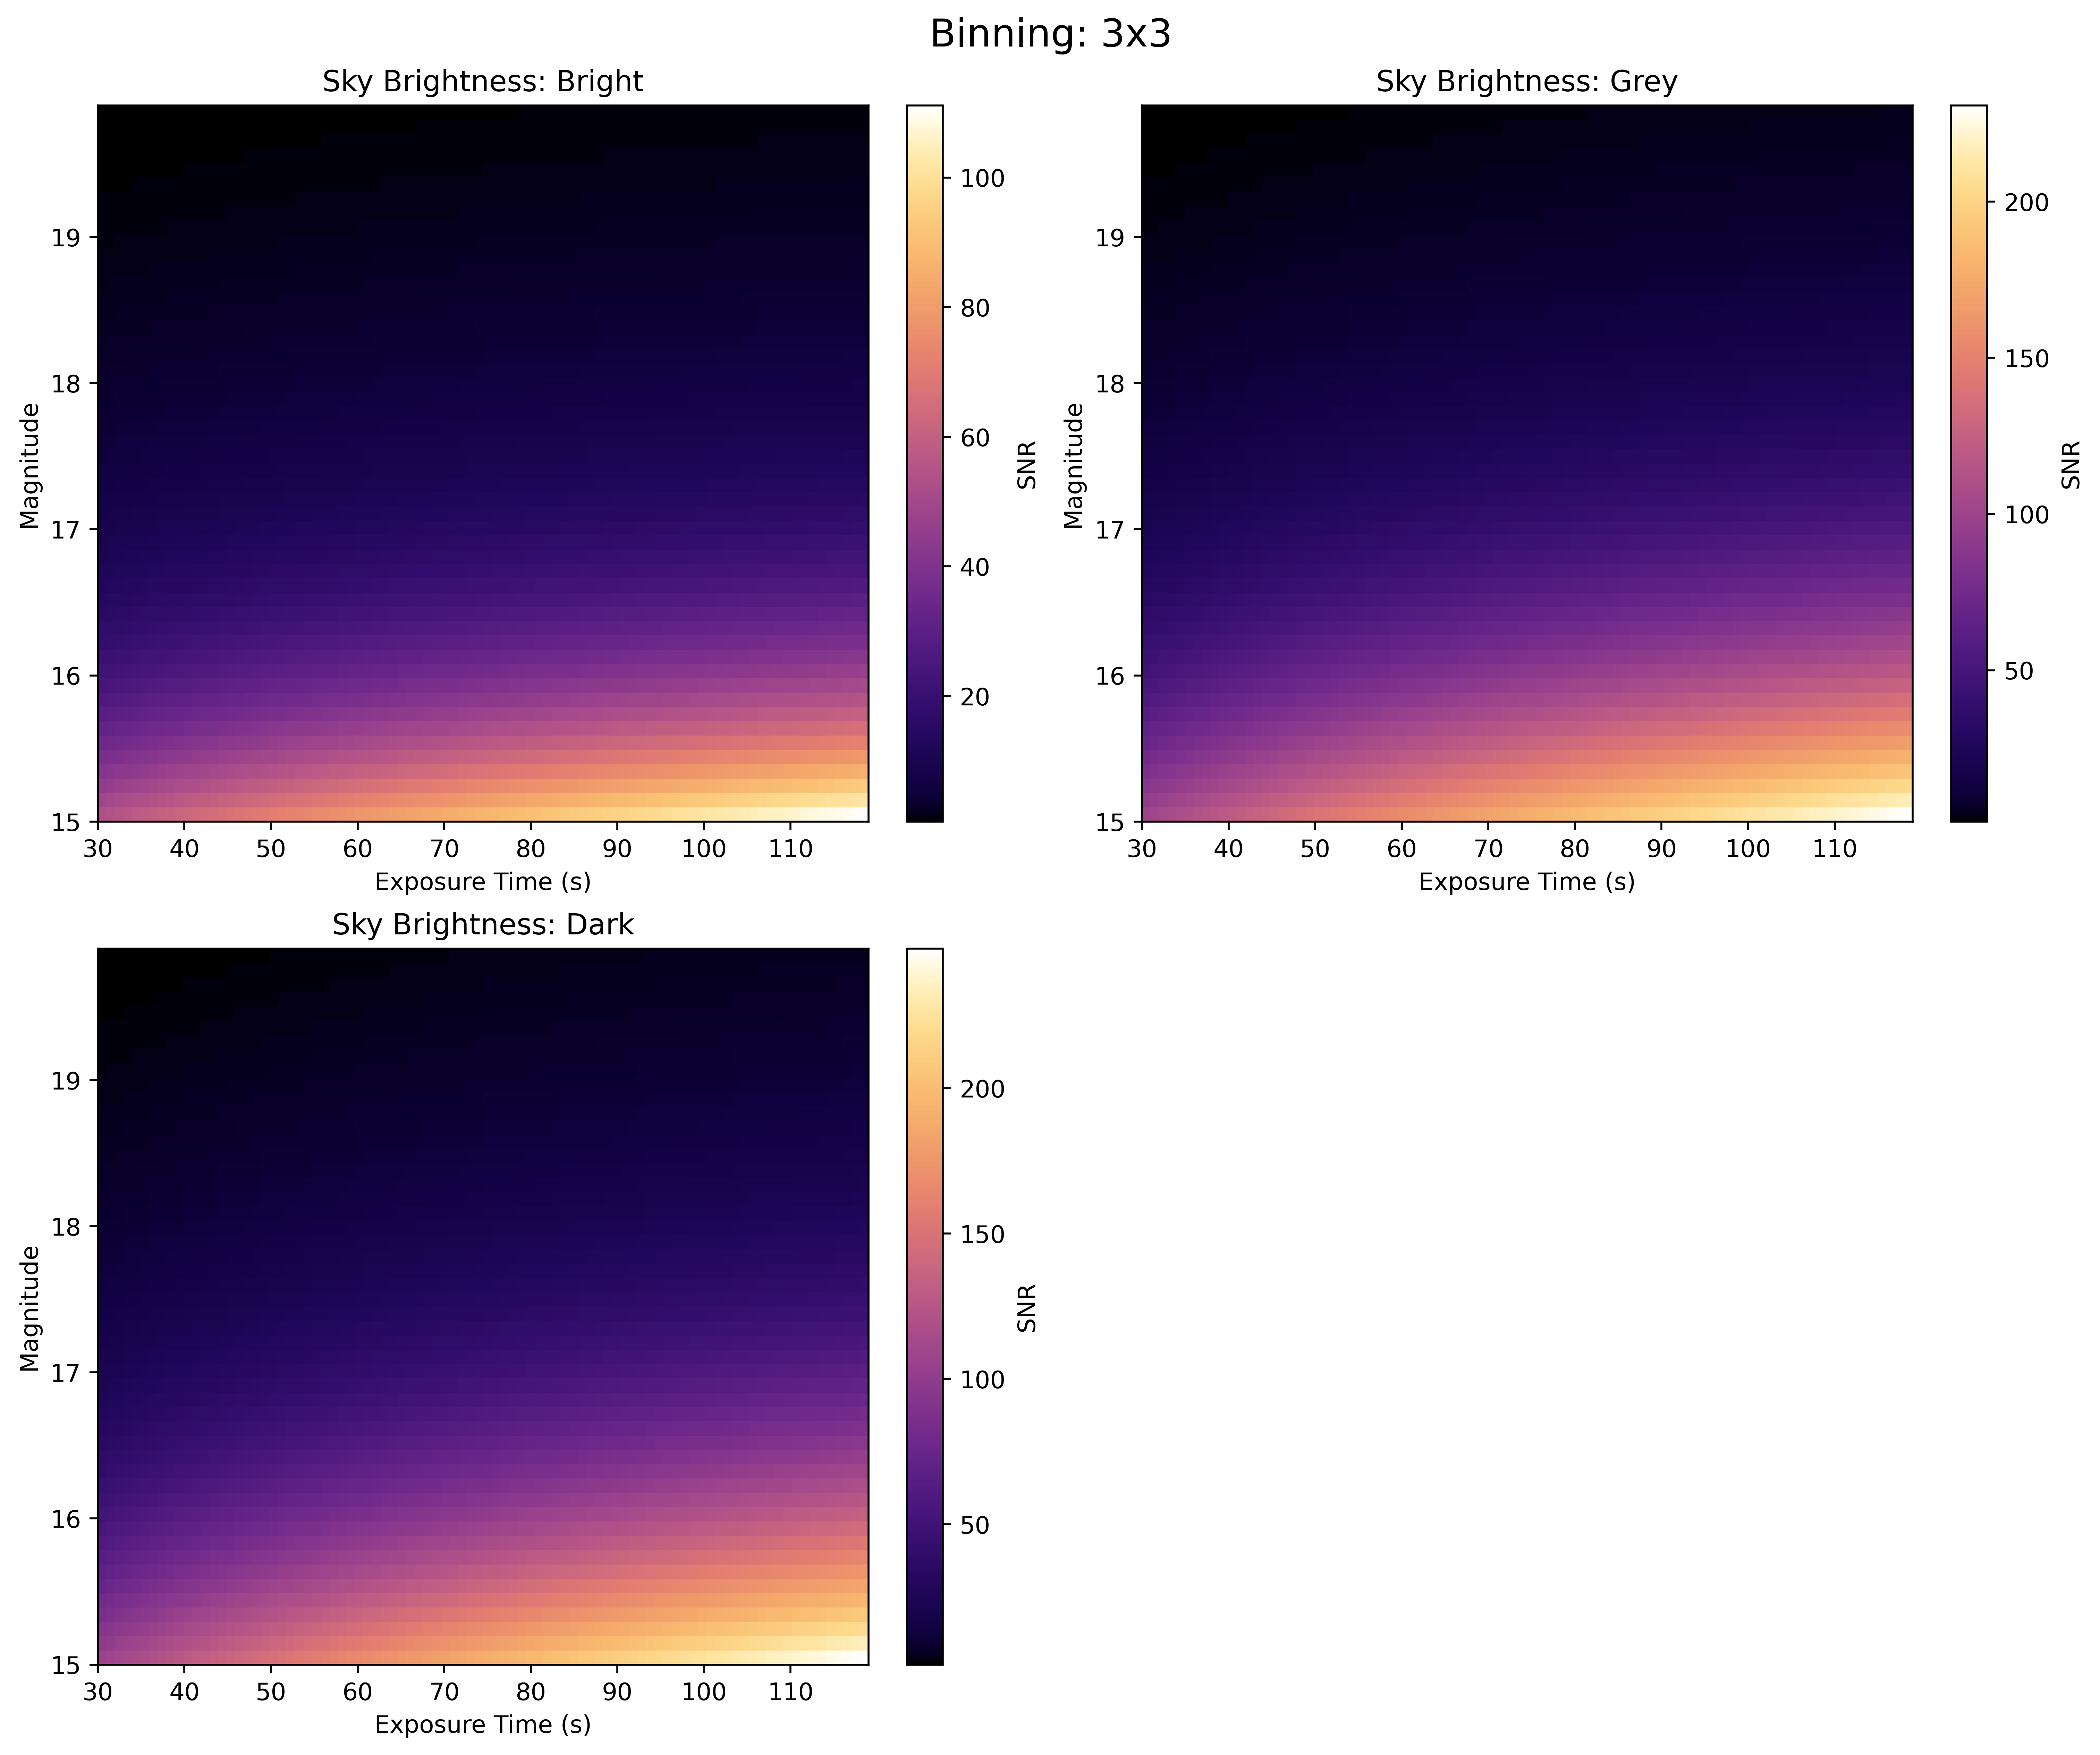

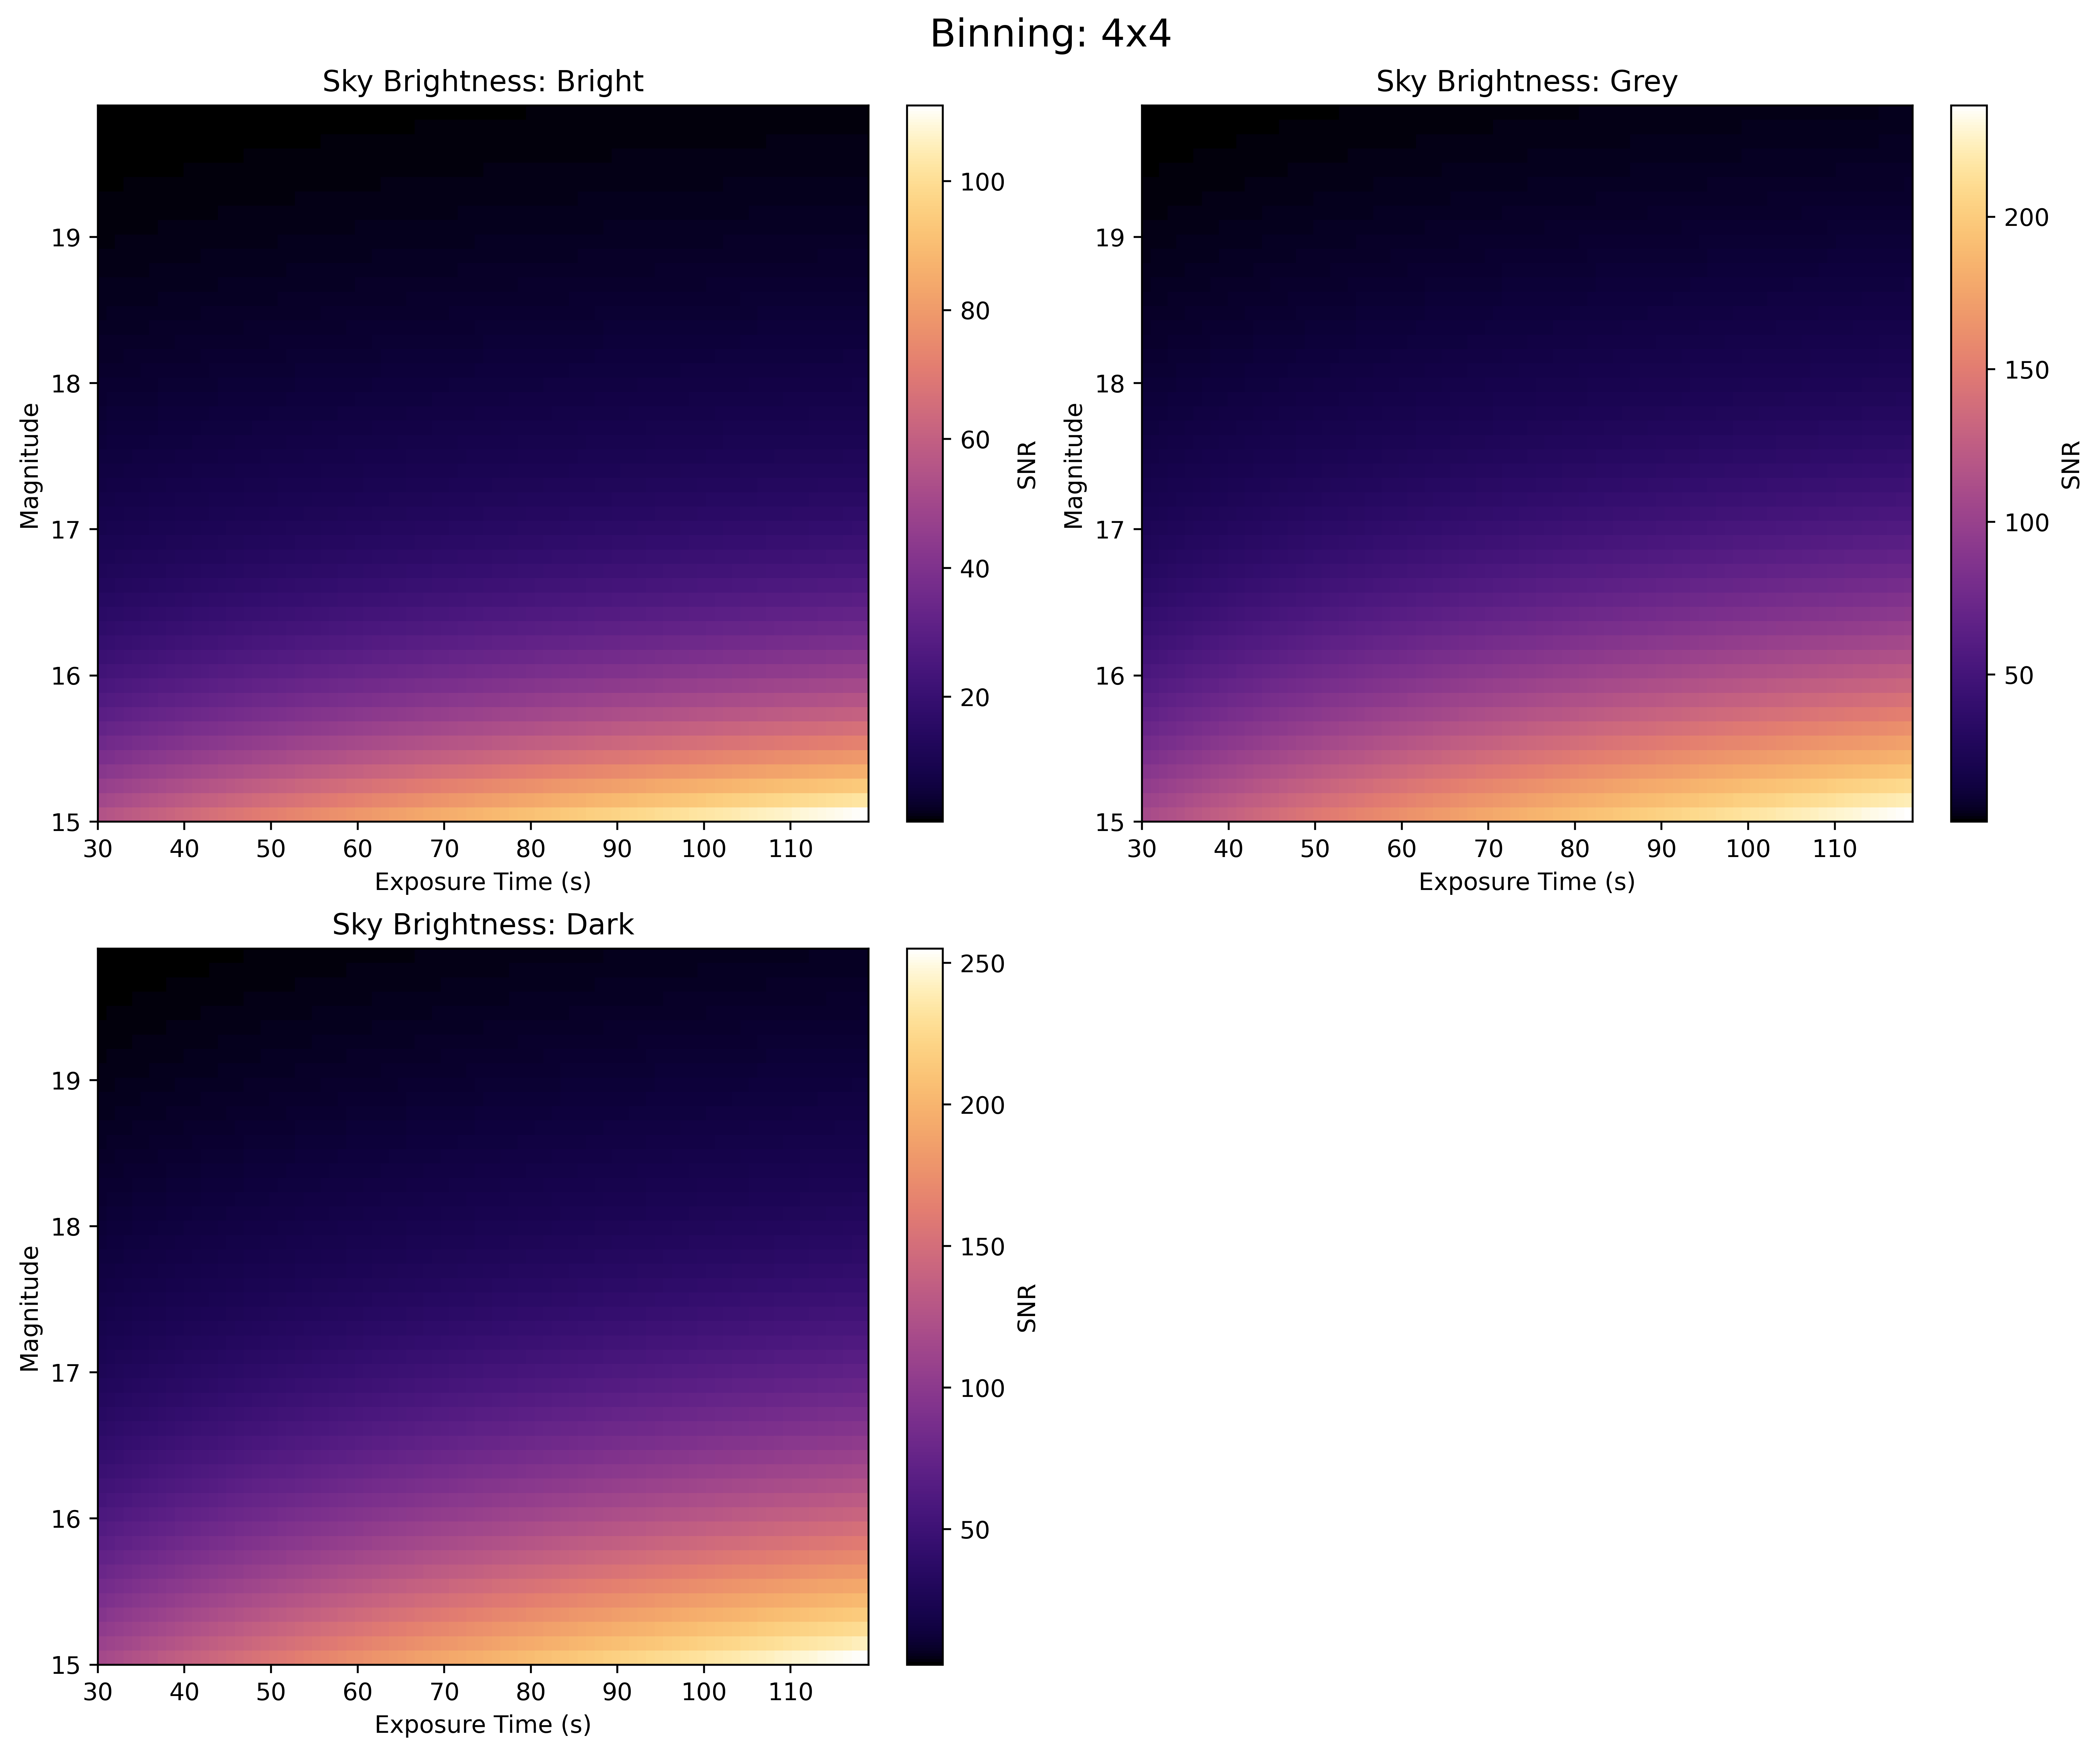

In [74]:
import cmastro

seeing = 3 * u.arcsec # Non point like source due to seeing

# Median seeing at site is 1.3"
#seeing = 1.3 * u.arcsec
aperture_area = np.pi * (1.5 * seeing) ** 2

# Want to produce one separate figure for each sky brightness
# in each figure we'll plot 4 subplots, one for each binning
# The axes will be the same for all plots: magnitude, exposure time, and SNR
sky_brightness = ['bright', 'grey', 'dark']

magnitudes = np.arange(start=15, stop=20, step=0.1)
exposure_times = np.arange(start=30, stop=120, step=1) * u.s

for j, binning in enumerate([1, 2, 3, 4]):
    # Create 3d plots: 4 for each sky brightness (each binning)
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True, dpi = 500)
    axes = axes.flatten()

    for i, sky in enumerate(sky_brightness, start=0):
        snr_grid = np.zeros((len(magnitudes), len(exposure_times)))

        for k, mag in enumerate(magnitudes):
            for l, t_exp in enumerate(exposure_times):
                #aperture_area = np.pi * (1.5 * seeing[j]) ** 2  # Update aperture area for each seeing value
                snr_grid[k, l] = calc_snr(mag, 'v', t_exp, sky, binning, aperture_area).value

        im = axes[i].imshow(
            snr_grid, origin='lower', aspect='auto',
            extent=(exposure_times[0].value, exposure_times[-1].value, magnitudes[0], magnitudes[-1]),
            # cma:hesperia, cma:lacerta, cma:laguna, cma:emph, cma:unpt
            cmap = "cma:hesperia",
        )
        axes[i].set_title(f'Sky Brightness: {sky.capitalize()}')
        axes[i].set_xlabel('Exposure Time (s)')
        axes[i].set_ylabel('Magnitude')
        fig.colorbar(im, ax=axes[i], label='SNR')
    
    fig.delaxes(axes[-1])
    # fig.tight_layout()
    fig.suptitle(f'Binning: {binning}x{binning}', fontsize=16)
    #plt.savefig('figure.png', bbox_inches='tight')
    plt.savefig(f'./figure_combined_{binning}x{binning}.png', dpi=600)

plt.show()